In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from bs4 import BeautifulSoup
import nltk
from sklearn.preprocessing import LabelEncoder
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import pickle

In [2]:
#Get the dataset from the file
df = pd.read_csv('IMDB Dataset.csv')
#Test the dataste so i display the first 10 rows of the dataset
print(df.head(10))

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
5  Probably my all-time favorite movie, a story o...  positive
6  I sure would like to see a resurrection of a u...  positive
7  This show was an amazing, fresh & innovative i...  negative
8  Encouraged by the positive comments about this...  negative
9  If you like original gut wrenching laughter yo...  positive


In [3]:
#Labed postive = 1, negative =0
label = LabelEncoder()
df['sentiment'] = label.fit_transform(df['sentiment'])
# Download NLTK stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Nicholas\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
#Extracting reviews and sentiments to x and y
x = df['review']
y = df['sentiment']

In [5]:
# Initializing Porter Stemmer for stemming words
ps = PorterStemmer()
Corpus = []

# Preprocessing the review
for i in range(len(x)):
    # Remove HTML tags
    review_without_html = BeautifulSoup(x[i], 'html.parser').get_text()

    # Remove non-letter characters
    review = re.sub('[^a-zA-Z]', ' ', review_without_html)
    # make the word to lower cases
    review = review.lower()
    # Do tokenization with NLTK
    tokens = nltk.word_tokenize(review)  
    # Stemming
    tokens = [ps.stem(word) for word in tokens if word not in set(stopwords.words('english'))]
    review = ' '.join(tokens)
    Corpus.append(review)

C:\Users\Nicholas\AppData\Local\Temp\ipykernel_18980\1377396736.py:6: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  review_without_html = BeautifulSoup(x[i], 'html.parser').get_text()


In [6]:
# Create a TF-IDF vectorizer with a maximum 5000 features
cv = TfidfVectorizer(max_features = 5000)
x = cv.fit_transform(Corpus)
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)



In [7]:
#Train the Naive Bayes model
mnb = MultinomialNB()
mnb.fit(X_train, y_train)
# Make predictions on the test set
pred = mnb.predict(X_test)

In [8]:
#Print the accuracy and metrics
print(accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

# Create a DataFrame to display actual and predicted sentiments
pd.DataFrame(np.c_[y_test, pred], columns=['Actual', 'Predicted'])

0.8512
[[4179  782]
 [ 706 4333]]
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      4961
           1       0.85      0.86      0.85      5039

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000



,Actual,Predicted
0,1,1
1,1,1
2,0,0
3,1,1
4,0,0
...,...,...
9995,0,0
9996,1,1
9997,1,0
9998,0,0


In [9]:
# Save the vectorizer and the trained model with pickle
pickle.dump(cv, open('count-Vectorizer.pkl', 'wb'))
pickle.dump(mnb, open('Movies_Review_Classification.pkl', 'wb'))
# Load the saved vectorizer and model
save_vectorizer = pickle.load(open('count-Vectorizer.pkl', 'rb'))
model = pickle.load(open('Movies_Review_Classification.pkl', 'rb'))
# The function to test the model with new review
def test_model(sentence):
    sen = save_vectorizer.transform([sentence]).toarray()
    res = model.predict(sen)[0]
    if res == 1:
        return 'Positive review'
    else:
        return 'negative review'
sen = 'This is the good movie'
res = test_model(sen)
print(res)

Positive review


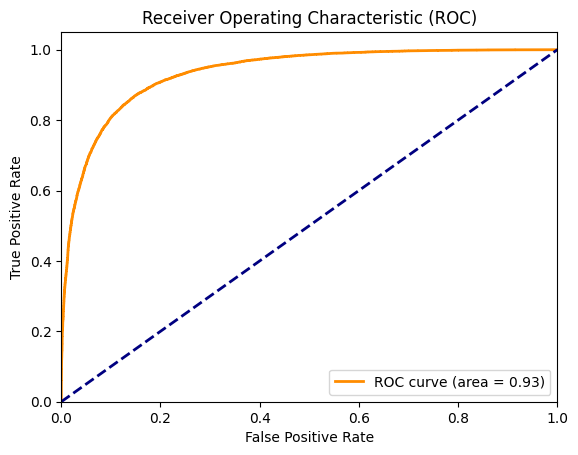

In [10]:
# ROC Analysis
fpr, tpr, _ = roc_curve(y_train, mnb.predict_proba(X_train)[:, 1])
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()